# Sensitivity to seasonal smoothing

This notebook compares the strengths and components across the nine seasonal windows. It reads archived tables by default. To inspect reconstructed tables, run the products command below and set RBC_PRODUCTS_DIR to its absolute output path before starting the kernel.

In [1]:
from pathlib import Path
import os,sys,json
ROOT = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config.json').exists())
sys.path.insert(0,str(ROOT))
WORK = Path(os.environ.get('RBC_OUTPUT',ROOT/'work')).resolve()
os.environ['RBC_OUTPUT']=str(WORK)
import pandas as pd
from IPython.display import display,SVG
from dados import CFG


## Compare windows with the same representatives

The seasonal window smooths a given position of the annual cycle across years. Changing its length does not change which pixel supplies an observation. The representatives, annual period, trend and low-pass windows and robust weighting remain fixed.

The tables report changes in seasonal and trend strength, component root mean square error relative to window 7, and interannual dispersion of the seasonal component. Domain summaries are medians over correlated bands in visible (VIS), red edge (RE), near infrared (NIR) and shortwave infrared (SWIR).

```text
python vigente.py products --work rebuilt-complete --source-work work --output-dir rebuilt-products
```

The output directory must be new. RBC_PRODUCTS_DIR selects that directory for this notebook; when it is unset, the notebook reads `work/artigo/`.

FS                            FT                    
classe                1         2         9         1         2         9
domain window                                                            
NIR    7       0.421248  0.315038  0.169329  0.047642  0.037110  0.007014
       9       0.400119  0.288434  0.160174  0.047636  0.026242  0.002869
       11      0.375959  0.270478  0.158133  0.044545  0.024925  0.003059
       13      0.362531  0.250269  0.148845  0.041036  0.027005  0.012530
       15      0.352700  0.231879  0.147708  0.039739  0.030138  0.011597
       21      0.347512  0.208432  0.142351  0.039278  0.022798  0.009878
       25      0.347183  0.206912  0.144162  0.040685  0.023361  0.011110
       31      0.341291  0.204955  0.143576  0.038975  0.023306  0.011639
       35      0.340277  0.203819  0.141618  0.038482  0.023091  0.011486
RE     7       0.354524  0.329128  0.210784  0.037802  0.052245  0.004994
       9       0.342802  0.298147  0.210860  0.030375  0.031703  0.006445
       11      0.316375  0.277651  0.197700  0.023534  0.000000  0.018324
       13      0.295800  0.273912  0.203651  0.018789  0.000000  0.014412
       15      0.284903  0.257075  0.199468  0.016941  0.012493  0.016174
       21      0.267911  0.247989  0.205805  0.009542  0.012224  0.015097
       25      0.270903  0.245272  0.207115  0.008007  0.011945  0.017016
       31      0.270382  0.242252  0.195477  0.007641  0.010986  0.017067
       35      0.269611  0.241619  0.195564  0.007314  0.010994  0.016989
SWIR   7       0.315372  0.394340  0.328122  0.047243  0.075823  0.071642
       9       0.290608  0.375452  0.291146  0.043718  0.070534  0.064013
       11      0.268026  0.355668  0.277216  0.045580  0.064023  0.062591
       13      0.268299  0.325487  0.267863  0.047318  0.054338  0.059187
       15      0.264412  0.317732  0.264636  0.046559  0.051832  0.057943
       21      0.263212  0.299830  0.262977  0.046296  0.047793  0.057958
       25      0.262466  0.298379  0.261891  0.046086  0.049006  0.057575
       31      0.261823  0.296843  0.260973  0.045901  0.049476  0.057229
       35      0.261323  0.296447  0.260646  0.045719  0.049816  0.057108
VIS    7       0.332601  0.438600  0.306970  0.055800  0.037307  0.013338
       9       0.344357  0.405473  0.277246  0.056916  0.034700  0.009689
       11      0.347909  0.401168  0.266354  0.060754  0.025313  0.009224
       13      0.345399  0.409500  0.259165  0.065837  0.026714  0.016913
       15      0.343386  0.412664  0.256325  0.070912  0.027873  0.017040
       21      0.339162  0.407628  0.252244  0.073015  0.033429  0.017103
       25      0.339482  0.406242  0.251142  0.075436  0.044766  0.017082
       31      0.336641  0.405174  0.250288  0.075764  0.045470  0.017070
       35      0.335720  0.404786  0.249977  0.075171  0.045759  0.017074

,FS_range,FT_range,seasonal_nrmse,trend_nrmse,residual_nrmse,phase_ratio
classe,,,,,,
1,0.050777,0.014415,0.450410,0.299463,0.410805,0.686607
2,0.087662,0.033218,0.521089,0.369864,0.480166,0.814118
9,0.054359,0.011200,0.447649,0.330448,0.409585,0.805556


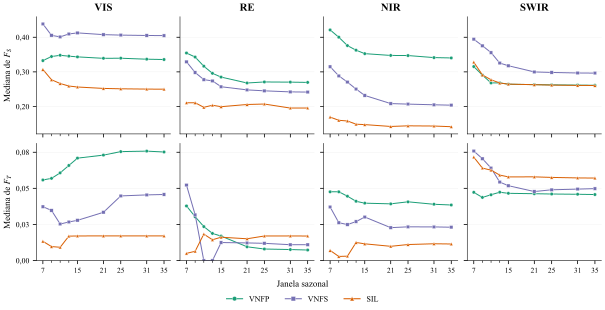

In [2]:
PRODUCTS=Path(os.environ.get('RBC_PRODUCTS_DIR',WORK/'artigo'))
d=pd.read_csv(PRODUCTS/'dominios.csv')
display(d.pivot(index=['domain','window'],columns='classe',values=['FS','FT']))
display(pd.read_csv(PRODUCTS/'sensibilidade_componentes.csv').groupby('classe').median(numeric_only=True))
FIGURES=PRODUCTS/'figuras' if os.environ.get('RBC_PRODUCTS_DIR') else ROOT/'editorial_figures/figuras'
display(SVG(filename=str(FIGURES/'figura_5_sensibilidade.svg')))


## Read magnitude and ordering together

The NIR and red-edge domain medians retain VNFP > VNFS > SIL for F_S in all nine windows. Their magnitudes still vary with smoothing. The component table summarises variation across bands within a class; those bands are not independent replicates. The displayed figure comes from the same archived or reconstructed product set as the tables.

## References

STL smoothing: Cleveland et al. (1990). Fixed settings and diagnostics: `METHODOLOGY.md`; strength measures: https://doi.org/10.1007/s10618-005-0039-x .